In [1]:
%load_ext autoreload 
%autoreload 2

# Fine-tuning on Pre-trained Model for Cell-type Annotation
In this tutorial, we demonstrate how to fine-tune a pre-trained model for cell type annotation. We use the CITE BMMC S1 dataset which contains both RNA and ADT measurements.

We summarize the fine-tuning pipeline in the following steps, which can be used as general recipe for fine-tuning on cell type annotation task and beyond:

    1. Specify hyper-parameter setup for cell type annotation
    2. Load and pre-process data
    3. Load the pre-trained scPMMI model
    4. fine-tune scPMMI with task-specific objectives
    5. Evaluate fine-tuned scPMMI

In [2]:
import sys
sys.path.append("..")

import warnings
warnings.filterwarnings('ignore')

import os
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import muon as mu
import scanpy as sc
import muon as mu
import random
from tqdm import tqdm
from typing import Tuple
from scipy.sparse import issparse
import swanlab
import matplotlib.pyplot as plt

import torch
from torch import optim, Tensor, nn
from torch.utils.data import DataLoader, Dataset
from torch.amp.autocast_mode import autocast
from transformers.optimization import get_scheduler

from scpmmi.utils.unify import align_to_common_proteins, align_to_common_genes
from scpmmi.tokenizer.vocab import Vocab
from scpmmi.models.scPMMI import scPMMI
from scpmmi.loss import ContrastiveLoss
from scpmmi.utils.util import set_seed
from scpmmi import logger

## Step 1: Specify her-parameter setup for integration task

In [3]:
hyperparameter_defaults = dict(
    task='cell_type_annotation',
    seed=42,
    dataset='cite_bmmc_s1',
    load_model = '../ckpt/ckpt_protra',
    gene_vocab='../config_file/default_gene_vocab.json',
    protein_vocab='../config_file/default_protein_vocab.json',
    batch_size=64,
    num_workers=0,
    temperature=0.01,
    alpha=1.5,
    n_epochs=15,
    lr=1.5e-4,
    weight_decay=0.05,
)

In [4]:
run = swanlab.init(
    project="scPMMI-fine-tuning",
    experiment_name=f"fine-tuning-{time.strftime('%b%d-%H-%M')}",
    config=hyperparameter_defaults,
    reinit=True,
    mode="offline"
)
config = run.config
print(config)
set_seed(config.seed)

swanlab: Tracking run with swanlab version 0.6.8

swanlab: Run data will be saved locally in 
/mnt/disk2/zyuan/code/scPMMI/tutorials/swanlog/run-20260125_171237-ccdm9p1qd4oazxfk7b7ng

swanlab: Backing up run fine-tuning-Jan25-17-12 locally

swanlab:  ☁️ Run `swanlab sync 
/mnt/disk2/zyuan/code/scPMMI/tutorials/swanlog/run-20260125_171237-ccdm9p1qd4oazxfk7b7ng` to sync logs to remote 
server

{'task': 'cell_type_annotation', 'seed': 42, 'dataset': 'cite_bmmc_s1', 'load_model': '../ckpt/ckpt_protra', 'gene_vocab': '../config_file/default_gene_vocab.json', 'protein_vocab': '../config_file/default_protein_vocab.json', 'batch_size': 64, 'num_workers': 0, 'temperature': 0.01, 'alpha': 1.5, 'n_epochs': 15, 'lr': 0.00015, 'weight_decay': 0.05}


In [5]:
dataset_name = config.dataset
save_path = Path(f"./result/save_celltype_annotation/dev_{dataset_name}-{time.strftime('%b%d-%H-%M')}/")
save_path.mkdir(parents=True, exist_ok=True)
print(f"save to {save_path}")

save to result/save_celltype_annotation/dev_cite_bmmc_s1-Jan25-17-12


## Step 2: Load and pre-process data

### 2.1 load data

In [6]:
if config.dataset == "cite_bmmc_s1":
    mdata = mu.read_h5mu(Path("../data/mdata/rna_adt/CITE_BMMC_S1_raw.h5mu"))

    adata_rna = mdata.mod['rna'] # type: ignore
    adata_adt = mdata.mod['adt'] # type: ignore
    adata_rna.X = adata_rna.layers['counts']
    adata_adt.X = adata_adt.layers['counts']
    
    adata_rna.obs['istrain'] = 'test'
    adata_adt.obs['istrain'] = 'test'
    adata_rna.obs.loc[adata_rna.obs['batch'].isin(['s1d1']), 'istrain'] = 'train'
    adata_adt.obs.loc[adata_adt.obs['batch'].isin(['s1d1']), 'istrain'] = 'train'

elif config.dataset == "cite_bmmc_s4":
    mdata = mu.read_h5mu(Path("../data/mdata/rna_adt/CITE_BMMC_S4_raw.h5mu"))

    adata_rna = mdata.mod['rna'] # type: ignore
    adata_adt = mdata.mod['adt'] # type: ignore
    adata_rna.X = adata_rna.layers['counts']
    adata_adt.X = adata_adt.layers['counts']
    adata_rna.obs['istrain'] = 'test'
    adata_adt.obs['istrain'] = 'test'
    adata_rna.obs.loc[adata_rna.obs['batch'] == 's4d1', 'istrain'] = 'train'
    adata_adt.obs.loc[adata_adt.obs['batch'] == 's4d1', 'istrain'] = 'train' 

else:
    raise ValueError(f"Unknown dataset {config.dataset}")
    
adata_rna, adata_adt

(AnnData object with n_obs × n_vars = 11126 × 13953
     obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train', 'istrain'
     var: 'feature_types', 'gene_id'
     uns: 'dataset_id', 'genome', 'organism'
     obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap'
     layers: 'counts',
 AnnData object with n_obs × n_vars = 11126 × 134
     obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', '

### 2.2 Match the gene and peak sets to the pre-trained model

In [7]:
gene_vocab = Vocab.from_file(config.gene_vocab)
gene_list = gene_vocab.get_token_list()
gene_ids = gene_vocab(gene_list)
adata_rna = align_to_common_genes(adata_rna, gene_list)    

2026-01-25 17:12:38 - scPMMI - INFO - Number of matched genes: 12316


In [8]:
protein_vocab = Vocab.from_file(config.protein_vocab)
protein_list = protein_vocab.get_token_list()
protein_ids = protein_vocab(protein_list)
adata_adt = align_to_common_proteins(adata_adt, protein_list)

2026-01-25 17:12:49 - scPMMI - INFO - Number of matched proteins: 134


## Step 3: Load the pre-trained scPMMI model

In [9]:
n_cls = len(adata_rna.obs['cell_type'].unique())
device = 'cuda:2'
torch.cuda.set_device(device)
dtype = torch.bfloat16
model_dir = Path(config.load_model)
model_config_file = model_dir / "config.json"
model_ckpt = model_dir / "model.bin"
with open(model_config_file, "r") as f:
    model_config = json.load(f)

model = scPMMI(
    model_config,
    n_cls=n_cls
)

if config.load_model is not None:
    try:
        model.load_state_dict(torch.load(model_ckpt))
        logger.info(f"Loading all model params from {model_ckpt}")
    except:
        # only load params that are in the model and match the size
        model_dict = model.state_dict()
        pretrained_dict = torch.load(model_ckpt)
        pretrained_dict = {
            k: v
            for k, v in pretrained_dict.items()
            if k in model_dict and v.shape == model_dict[k].shape
        }
        for k, v in pretrained_dict.items():
            logger.info(f"Loading params {k} with shape {v.shape}")
        model_dict.update(pretrained_dict)
        model.load_state_dict(model_dict)
model = model.to(device, dtype)

2026-01-25 17:12:52 - scPMMI - INFO - Loading params encoder_mod1.backbone.embedding.cls_token with shape torch.Size([1, 1, 512])
2026-01-25 17:12:52 - scPMMI - INFO - Loading params encoder_mod1.backbone.embedding.patch_position_embeddings with shape torch.Size([1, 160, 512])
2026-01-25 17:12:52 - scPMMI - INFO - Loading params encoder_mod1.backbone.embedding.embedding.weight with shape torch.Size([40957, 512])
2026-01-25 17:12:52 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.norm.weight with shape torch.Size([512])
2026-01-25 17:12:52 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.mixer.Wqkv.weight with shape torch.Size([1536, 512])
2026-01-25 17:12:52 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.mixer.Wqkv.bias with shape torch.Size([1536])
2026-01-25 17:12:52 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.mixer.out_proj.weight with shape torch.Size([512, 512])
2026-01-25 17:12:52 - scPMMI - INFO - Loading params

## Step 4: Fine-tune scPMMI with task-specific objectives

In [10]:
class MultiSeqDataset(Dataset):
    def __init__(
        self,
        X_mod1: np.ndarray,
        feature_ids_mod1: list,
        X_mod2: np.ndarray,
        feature_ids_mod2: list,
        celltype_ids,
    ):
        """
        PyTorch-compatible dataset for paired multi-modal single-cell sequencing data.

        Args:
            adata_mod1: AnnData object for the first modality (e.g., RNA).
            layer_mod1: Layer name in adata_mod1 to use as input.
            adata_mod2: AnnData object for the second modality (e.g., adt).
            layer_mod2: Layer name in adata_mod2 to use as input.
        """
        self.feature_ids_mod1 = torch.tensor(feature_ids_mod1, dtype=torch.int32)
        self.feature_ids_mod2 = torch.tensor(feature_ids_mod2, dtype=torch.int32)
        celltype_labels = torch.tensor(celltype_ids, dtype=torch.long)
        # ---------------------- Process first modality ----------------------
        values_mod1 = torch.tensor(X_mod1)
        values_mod1 = torch.log1p(values_mod1 / values_mod1.sum(1)[:, None] * 1e4)
        tokens_mod1 = self.feature_ids_mod1.unsqueeze(0).repeat(values_mod1.shape[0], 1)
        
        # ---------------------- Process second modality ----------------------
        values_mod2 = torch.tensor(X_mod2)
        values_mod2 = torch.log1p(values_mod2 / values_mod2.sum(1)[:, None] * 1e3)

        tokens_mod2 = self.feature_ids_mod2.unsqueeze(0).repeat(values_mod2.shape[0], 1)
        
        # ---------------------- Store both modalities ----------------------
        self.data = {
            "mod1_token_ids": tokens_mod1,
            "mod1_values": values_mod1,

            "mod2_token_ids": tokens_mod2,
            "mod2_values": values_mod2,
            
            "labels": celltype_labels,
        }

    def __len__(self):
        return self.data["mod1_token_ids"].shape[0]

    def __getitem__(self, idx):
        return {k: v[idx] for k, v in self.data.items()}

In [11]:
train_ad_rna = adata_rna[adata_rna.obs['istrain'] == "train"]
test_ad_rna = adata_rna[~(adata_rna.obs['istrain'] == "train")]
train_ad_adt = adata_adt[adata_adt.obs['istrain'] == "train"]
test_ad_adt = adata_adt[~(adata_adt.obs['istrain'] == "train")]

unique_cell_types = sorted(set(adata_rna.obs['cell_type'].unique()))
celltype_to_idx = {ct: i for i, ct in enumerate(unique_cell_types)}
idx_to_celltype = {v: k for k, v in celltype_to_idx.items()}

cell_types_train = np.array(train_ad_rna.obs["cell_type"].tolist(), dtype=str)
celltype_labels_train = np.array([celltype_to_idx[ct] for ct in cell_types_train])

cell_types_test = np.array(test_ad_rna.obs["cell_type"].tolist(), dtype=str)
celltype_labels_test = np.array([celltype_to_idx[ct] for ct in cell_types_test])

In [12]:
from sklearn.model_selection import train_test_split

all_counts_rna = (
    train_ad_rna.X.toarray()     # type:ignore
    if issparse(train_ad_rna.X)
    else train_ad_rna.X
)
all_counts_adt = (
    train_ad_adt.X.toarray()     # type:ignore
    if issparse(train_ad_adt.X)
    else train_ad_adt.X
)
(
    train_data_rna,
    valid_data_rna,
    train_data_adt,
    valid_data_adt,
    train_celltype_labels,
    valid_celltype_labels,
) = train_test_split(
    all_counts_rna, all_counts_adt, celltype_labels_train, test_size=0.1, shuffle=True
)
train_dataset = MultiSeqDataset(X_mod1=train_data_rna, feature_ids_mod1=gene_ids, 
                            X_mod2=train_data_adt, feature_ids_mod2=protein_ids, celltype_ids=train_celltype_labels)
valid_dataset = MultiSeqDataset(X_mod1=valid_data_rna, feature_ids_mod1=gene_ids, 
                            X_mod2=valid_data_adt, feature_ids_mod2=protein_ids, celltype_ids=valid_celltype_labels)
train_dataloader = DataLoader(train_dataset, batch_size=config.batch_size, shuffle=False,
                    num_workers=config.num_workers, pin_memory=True)
valid_dataloader = DataLoader(valid_dataset, batch_size=config.batch_size, shuffle=False,
                    num_workers=config.num_workers, pin_memory=True)

In [13]:
all_train_dataset = MultiSeqDataset(X_mod1=all_counts_rna, feature_ids_mod1=gene_ids, 
                            X_mod2=all_counts_adt, feature_ids_mod2=protein_ids, celltype_ids=celltype_labels_train)

In [14]:
test_counts_rna = np.array(
    test_ad_rna.X.toarray()     # type:ignore
    if issparse(test_ad_rna.X)
    else test_ad_rna.X
)
test_counts_adt = np.array(
    test_ad_adt.X.toarray()     # type:ignore
    if issparse(test_ad_adt.X)
    else test_ad_adt.X
)

test_dataset = MultiSeqDataset(X_mod1=test_counts_rna, feature_ids_mod1=gene_ids, 
                            X_mod2=test_counts_adt, feature_ids_mod2=protein_ids, celltype_ids=celltype_labels_test)

test_dataloader = DataLoader(test_dataset, batch_size=config.batch_size, shuffle=False,
                    num_workers=config.num_workers, pin_memory=True)

In [15]:
criterion_clip = ContrastiveLoss(
    temperature=config.temperature, alpha=config.alpha
)
criterion_ce = nn.CrossEntropyLoss()
optimizer = optim.AdamW( # type: ignore
    model.parameters(), lr=config.lr, weight_decay=config.weight_decay
)
max_train_steps = config.n_epochs * len(train_dataloader)
num_warmup_steps = int(0.1 * max_train_steps)  # 10% steps for warmup
scheduler = get_scheduler(
    name="cosine",
    optimizer=optimizer,
    num_warmup_steps=num_warmup_steps,
    num_training_steps=max_train_steps,
)

In [16]:
def evaluate(model: nn.Module, loader: DataLoader) -> Tuple[float, float, float]:
    """
    Evaluate the model on the evaluation data.
    """
    model.eval()
    total_ce_loss = 0.0
    total_loss = 0.0
    total_error = 0.0
    total_num = 0
    with torch.no_grad():
        for batch_data in loader:
            mod1_token_ids = batch_data["mod1_token_ids"].to(device)
            mod1_values_input = batch_data["mod1_values"].to(device)
            mod2_token_ids = batch_data["mod2_token_ids"].to(device)
            mod2_values_input = batch_data["mod2_values"].to(device)
            labels = batch_data["labels"].to(device)

            with autocast(device_type="cuda", dtype=dtype):
                output = model(mod1_token_ids, mod1_values_input, mod2_token_ids, mod2_values_input, CLS=True)
                loss_clip = criterion_clip(output['cell_emb_mod1'], output['cell_emb_mod2'])
                loss_ce1 = criterion_ce(output['cls_output_mod1'], labels)
                loss_ce2 = criterion_ce(output['cls_output_mod2'], labels)
                loss = loss_clip + loss_ce1 + loss_ce2
            total_loss += loss.item()
            total_ce_loss += loss_ce1.item()
            accuracy = (output['cls_output_mod1'].argmax(1) == labels).sum().item()
            total_error += (1 - accuracy / len(mod1_token_ids)) * len(mod1_token_ids)
            total_num += len(mod1_token_ids)
    
    return total_loss / len(loader), total_ce_loss / len(loader), total_error / total_num

In [17]:
from torch.nn.utils import clip_grad_norm_
import copy

best_val_loss = float("inf")
global_step = 0
for epoch in range(config.n_epochs):
    model.train()
    loop = tqdm(train_dataloader, desc=f'Epoch [{epoch}/{config.n_epochs}]',leave=False)
    for step, batch_data in enumerate(loop):
        mod1_token_ids = batch_data["mod1_token_ids"].to(device)
        mod1_values_input = batch_data["mod1_values"].to(device)

        mod2_token_ids = batch_data["mod2_token_ids"].to(device)
        mod2_values_input = batch_data["mod2_values"].to(device)
        labels = batch_data["labels"].to(device)

        optimizer.zero_grad()
        with autocast(device_type="cuda", dtype=dtype):
            output = model(mod1_token_ids, mod1_values_input, mod2_token_ids, mod2_values_input, CLS=True)
            loss_clip = criterion_clip(output['cell_emb_mod1'], output['cell_emb_mod2'])
            loss_ce1 = criterion_ce(output['cls_output_mod1'], labels)
            loss_ce2 = criterion_ce(output['cls_output_mod2'], labels)
            loss = loss_clip + loss_ce1 + loss_ce2
        
        loss.backward()
        clip_grad_norm_(model.parameters(), max_norm=1.2)
        optimizer.step()
        scheduler.step()
        global_step += 1
        loop.set_postfix({
            "Step": global_step,
            "Loss": f"{loss.item():.4f}",
            "clip": f"{loss_clip.item():.4f}",
            "ce1": f"{loss_ce1.item():.4f}",
            "ce2": f"{loss_ce2.item():.4f}",
            "LR": f"{scheduler.get_last_lr()[0]:.2e}",
        })
                    
        swanlab.log({
            "train/loss_step": loss.item(),
            "clip": f"{loss_clip.item():.4f}",
            "ce1": f"{loss_ce1.item():.4f}",
            "ce2": f"{loss_ce2.item():.4f}",
            "step": global_step,
            "train/lr": scheduler.get_last_lr()[0],
        })
    val_loss, val_ce_loss, val_err = evaluate(model, valid_dataloader)
    logger.info("-" * 80)
    logger.info(
        f"| end of epoch {epoch:3d} | valid loss {val_loss:5.4f} "
        f"valid loss/ce {val_ce_loss:5.4f} | err {val_err:5.4f}"
    )
    logger.info("-" * 80)

    if val_ce_loss < best_val_loss:
        best_val_loss = val_ce_loss
        best_model = copy.deepcopy(model)
        best_model_epoch = epoch
        logger.info(f"Best model with score {best_val_loss:5.4f}")

Epoch [0/15]:   0%|          | 0/52 [00:00<?, ?it/s]

2026-01-25 17:13:31 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:13:31 - scPMMI - INFO - | end of epoch   0 | valid loss 3.4832 valid loss/ce 0.6000 | err 0.1181
2026-01-25 17:13:31 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:13:31 - scPMMI - INFO - Best model with score 0.6000


2026-01-25 17:13:44 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:13:44 - scPMMI - INFO - | end of epoch   1 | valid loss 3.5306 valid loss/ce 0.4217 | err 0.1456
2026-01-25 17:13:44 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:13:44 - scPMMI - INFO - Best model with score 0.4217


2026-01-25 17:13:57 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:13:57 - scPMMI - INFO - | end of epoch   2 | valid loss 2.9881 valid loss/ce 0.2150 | err 0.0412
2026-01-25 17:13:57 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:13:58 - scPMMI - INFO - Best model with score 0.2150


2026-01-25 17:14:11 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:14:11 - scPMMI - INFO - | end of epoch   3 | valid loss 2.8883 valid loss/ce 0.1864 | err 0.0412
2026-01-25 17:14:11 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:14:11 - scPMMI - INFO - Best model with score 0.1864


2026-01-25 17:14:24 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:14:24 - scPMMI - INFO - | end of epoch   4 | valid loss 2.6581 valid loss/ce 0.1714 | err 0.0302
2026-01-25 17:14:24 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:14:24 - scPMMI - INFO - Best model with score 0.1714


... (6 outputs left out)

2026-01-25 17:15:56 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:15:56 - scPMMI - INFO - | end of epoch  11 | valid loss 2.1950 valid loss/ce 0.1602 | err 0.0357
2026-01-25 17:15:56 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:15:56 - scPMMI - INFO - Best model with score 0.1602


2026-01-25 17:16:09 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:16:09 - scPMMI - INFO - | end of epoch  12 | valid loss 2.1600 valid loss/ce 0.1595 | err 0.0385
2026-01-25 17:16:09 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:16:09 - scPMMI - INFO - Best model with score 0.1595


2026-01-25 17:16:22 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:16:22 - scPMMI - INFO - | end of epoch  13 | valid loss 2.1697 valid loss/ce 0.1592 | err 0.0385
2026-01-25 17:16:22 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:16:22 - scPMMI - INFO - Best model with score 0.1592


2026-01-25 17:16:35 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:16:35 - scPMMI - INFO - | end of epoch  14 | valid loss 2.1648 valid loss/ce 0.1591 | err 0.0385
2026-01-25 17:16:35 - scPMMI - INFO - --------------------------------------------------------------------------------
2026-01-25 17:16:35 - scPMMI - INFO - Best model with score 0.1591


## Step 5: Inference and Evaluation

In [18]:
best_model.eval()        
# Test the model
test_loader = DataLoader(
    test_dataset, 
    batch_size=config.batch_size, 
    shuffle=False,
    num_workers=config.num_workers,
    pin_memory=True,
)
with torch.no_grad():
    rna_embs = []
    labels_pred = []
    for batch_data in tqdm(test_loader, desc="Inference"):
        mod1_token_ids = batch_data["mod1_token_ids"].to(device)
        mod1_values_input = batch_data["mod1_values"].to(device)

        mod2_token_ids = batch_data["mod2_token_ids"].to(device)
        mod2_values_input = batch_data["mod2_values"].to(device)
        labels = batch_data["labels"].to(device)

        output = best_model(mod1_token_ids, mod1_values_input, mod2_token_ids, mod2_values_input, CLS=True)
        
        label_pred = torch.argmax(output['cls_output_mod1'], dim=1)
        rna_embs.append(output['cell_emb_mod1'].cpu())
        labels_pred.append(label_pred.cpu())
    
    rna_embs = torch.cat(rna_embs, dim=0).to(torch.float32).numpy()
    labels_pred = torch.cat(labels_pred, dim=0).to(torch.long).numpy()
    labels_str_pred = [idx_to_celltype[int(i)] for i in labels_pred]

    test_ad_rna.obsm['scPMMI'] = rna_embs
    test_ad_rna.obs['cell_type_pred'] = labels_str_pred
    test_ad_rna_embs = sc.AnnData(X=rna_embs, obs=test_ad_rna.obs)

Inference:   0%|          | 0/118 [00:00<?, ?it/s]

Inference: 100%|██████████| 118/118 [00:11<00:00, 10.48it/s]


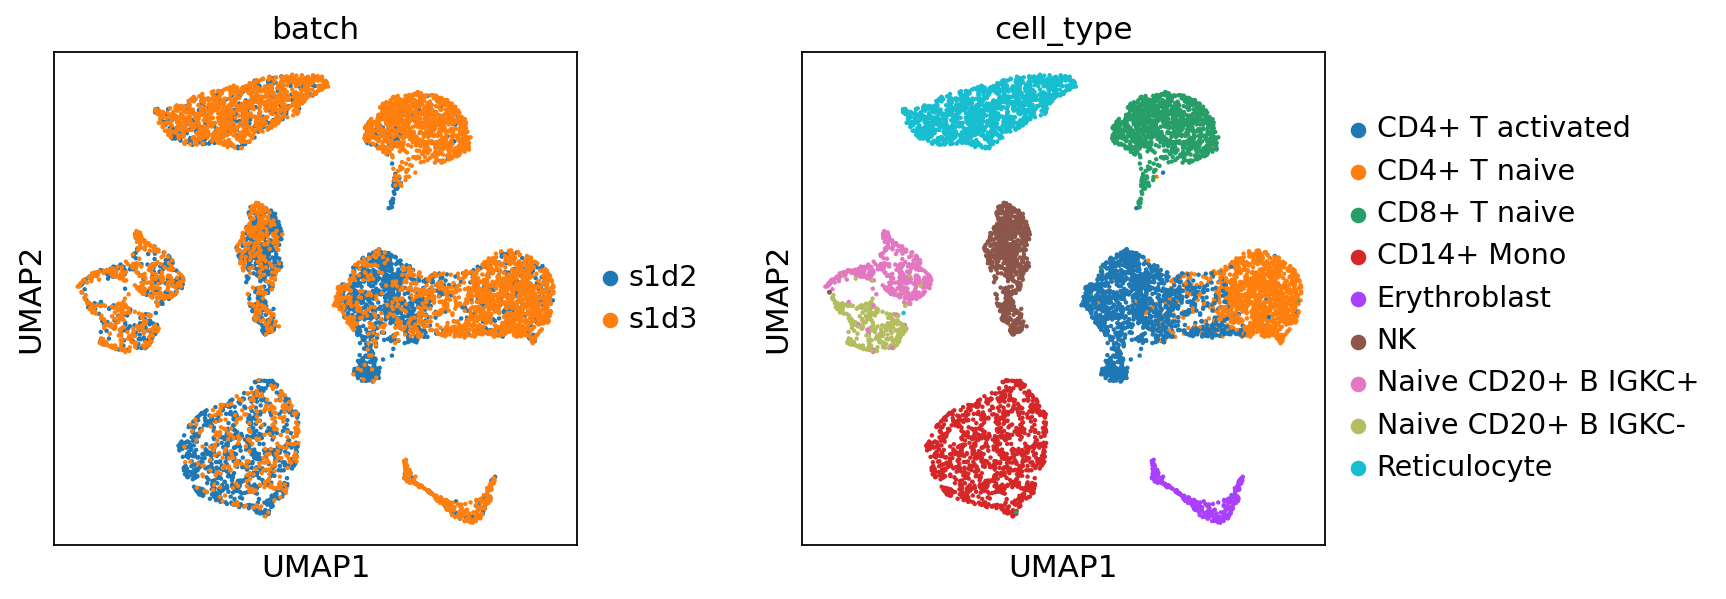

In [19]:
sc.set_figure_params(figsize=(4, 4))

EmbAdata = sc.AnnData(X=rna_embs, obs=test_ad_rna.obs)
sc.pp.neighbors(EmbAdata)

sc.tl.umap(EmbAdata, min_dist=0.5, spread=1.0)
if 'batch' in EmbAdata.obs.columns and len(set(EmbAdata.obs['batch'].unique())) > 1:
    sc.pl.umap(EmbAdata, color=['batch', 'cell_type'], ncols=2, wspace=0.3)
else:
    sc.pl.umap(EmbAdata, color=['cell_type'], ncols=2, wspace=0.3)
EmbAdata.write(save_path / "cell_emb.h5ad")

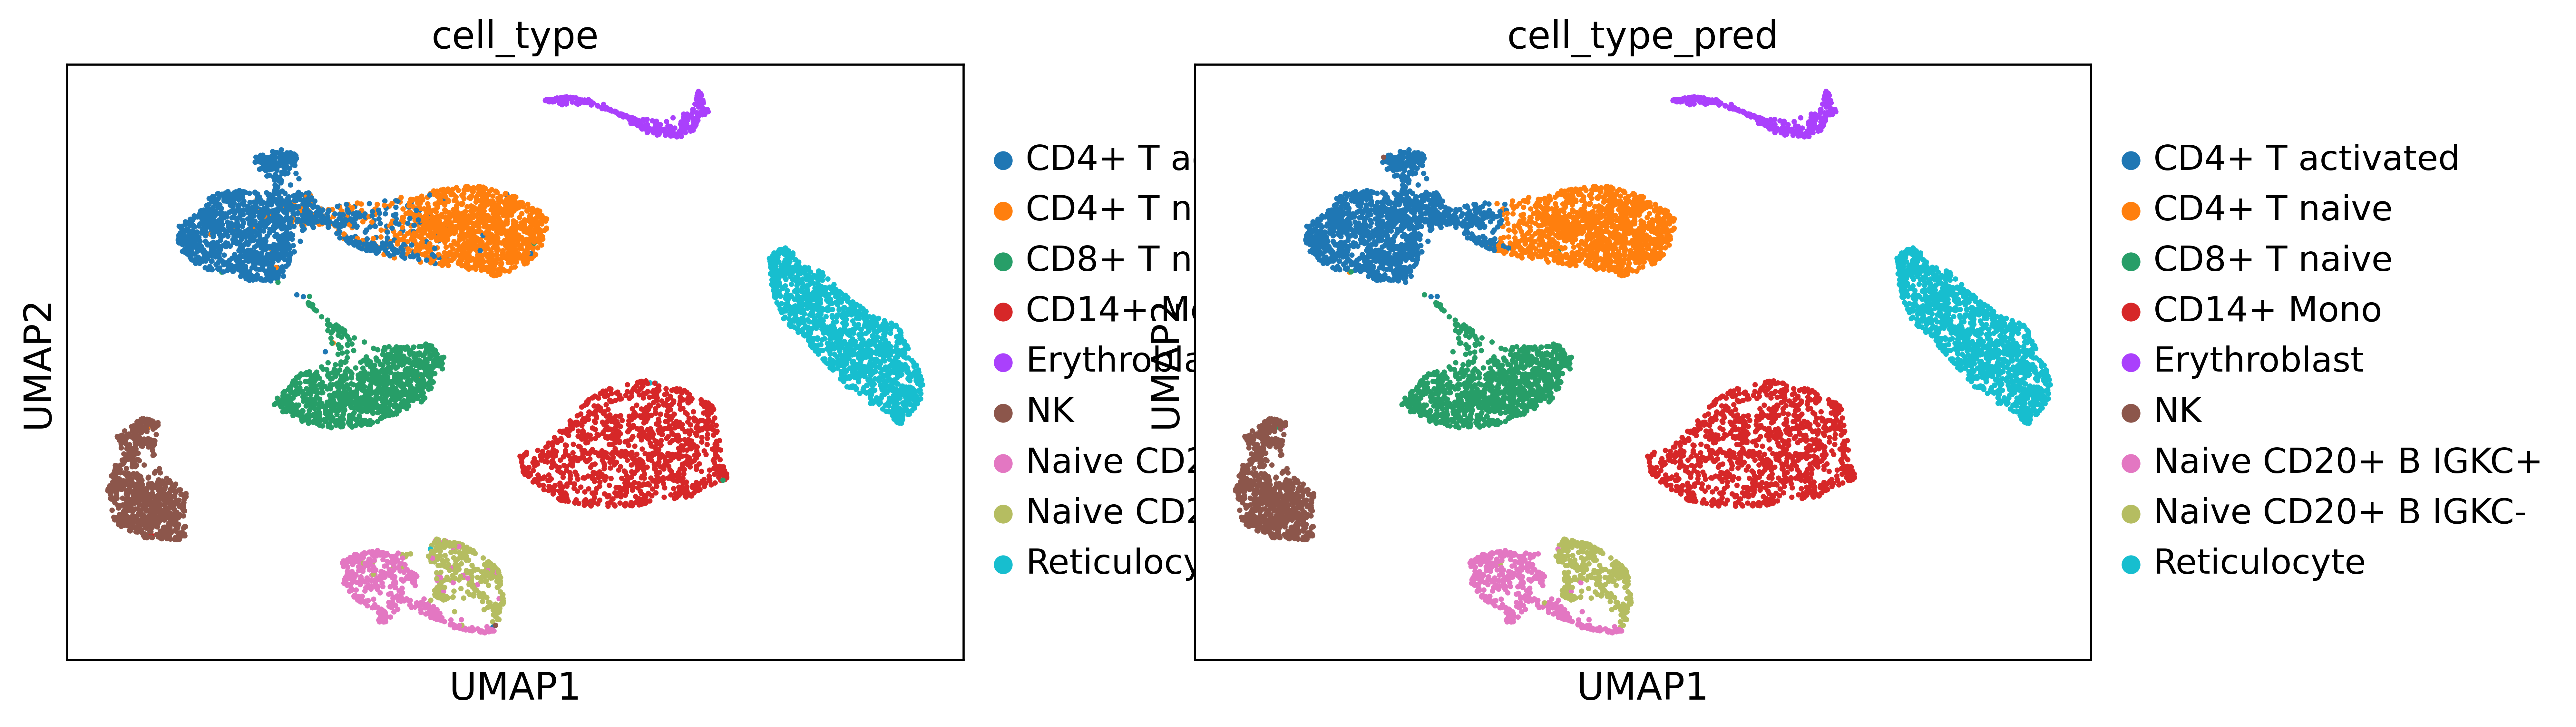

saving figure to file result/save_celltype_annotation/dev_cite_bmmc_s1-Jan25-17-12


In [20]:
sc.set_figure_params(figsize=(4, 4))
sc.settings.figdir = save_path
sc.pp.neighbors(test_ad_rna, metric="cosine", use_rep="scPMMI", n_neighbors=30)
sc.tl.umap(test_ad_rna, min_dist=0.5, spread=1.0)
with plt.rc_context({"figure.figsize": (6, 4), "figure.dpi": (300)}):
    sc.pl.umap(
        test_ad_rna,
        color=["cell_type", "cell_type_pred"],
        show=True
    )
test_ad_rna.write_h5ad(save_path /"test_data.h5ad")
print(f"saving figure to file {save_path}")

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

ct = test_ad_rna.obs['cell_type'].tolist()
ct_pred = test_ad_rna.obs['cell_type_pred'].tolist()

accuracy  = accuracy_score(ct, ct_pred)
precision = precision_score(ct, ct_pred, average="weighted")
recall    = recall_score(ct, ct_pred, average="weighted")
f1_macro  = f1_score(ct, ct_pred, average="macro")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"Macro F1 : {f1_macro:.4f}")

metric = {
    'acc': round(float(accuracy), 3),
    'precision': round(float(precision), 3),
    'recall': round(float(recall), 3),
    'Macro F1': round(float(f1_macro), 3)
}
with open(f'{save_path}/metrics.json', "w") as f:
    json.dump(metric, f, indent=4)

Accuracy : 0.9681
Precision: 0.9682
Recall   : 0.9681
Macro F1 : 0.9708


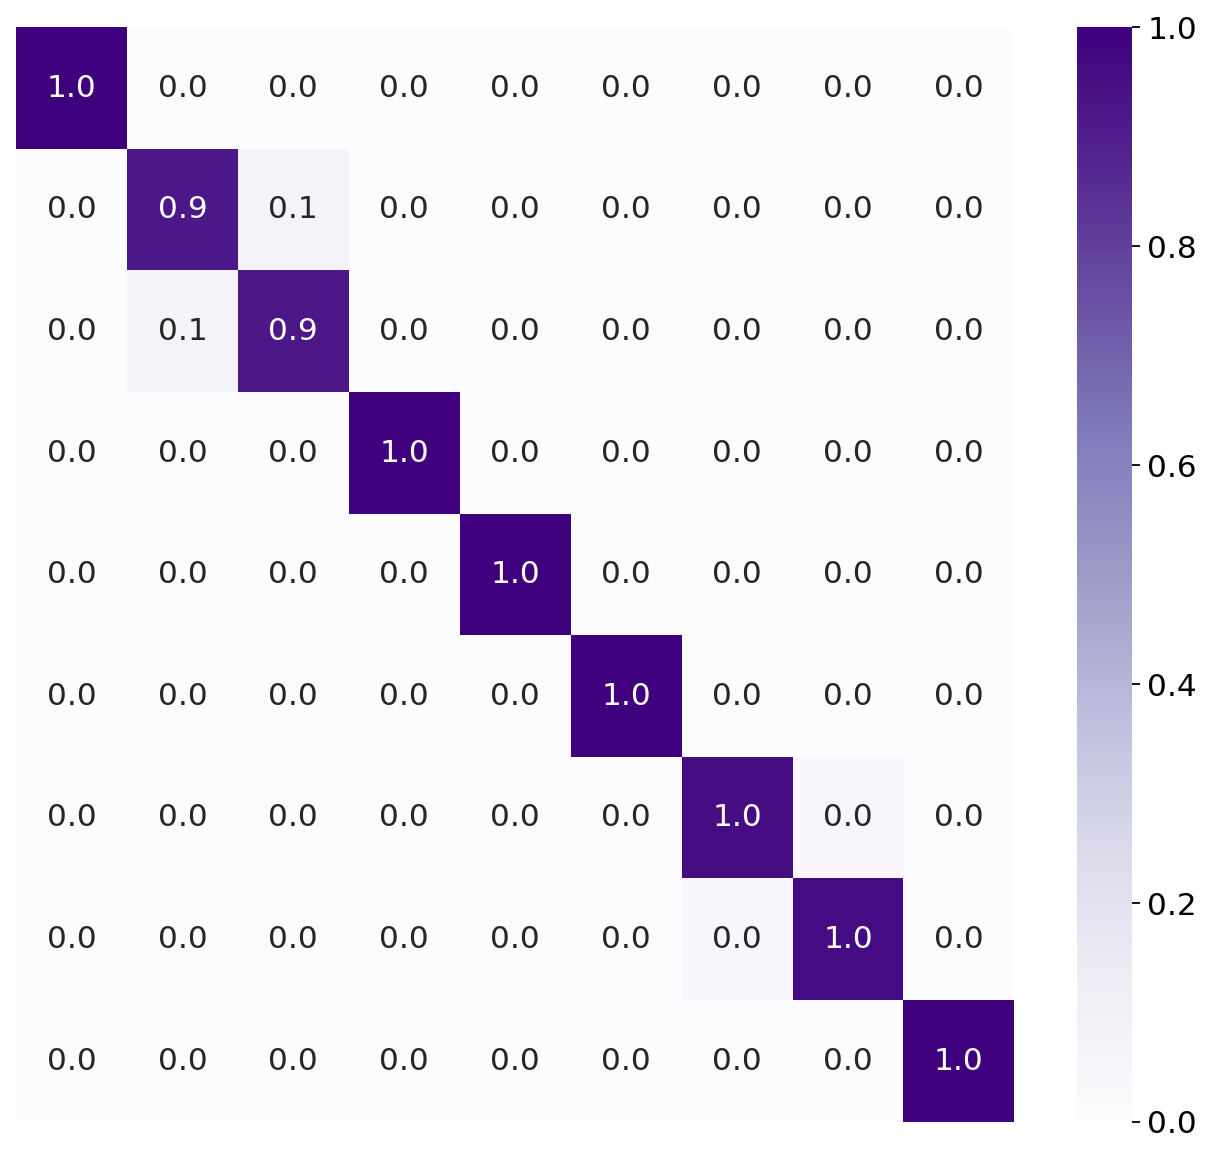

In [22]:
import seaborn as sns
from sklearn.metrics import confusion_matrix


fig, ax = plt.subplots(1, 1, figsize=(10, 9))
cm = confusion_matrix(
    test_ad_rna.obs['cell_type'].values, 
    test_ad_rna.obs['cell_type_pred'].values, 
    labels=np.unique(test_ad_rna.obs['cell_type'].values)
)
cm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
cm = pd.DataFrame(cm, index=np.unique(test_ad_rna.obs['cell_type'].values), columns=np.unique(test_ad_rna.obs['cell_type'].values))

sns.heatmap(
    cm, annot=True, fmt=".1f", 
    cmap="Purples",
    ax=ax
)
ax.set_xticks([])
ax.set_yticks([])
plt.savefig(save_path / "confusion_matrix.pdf", dpi=300)

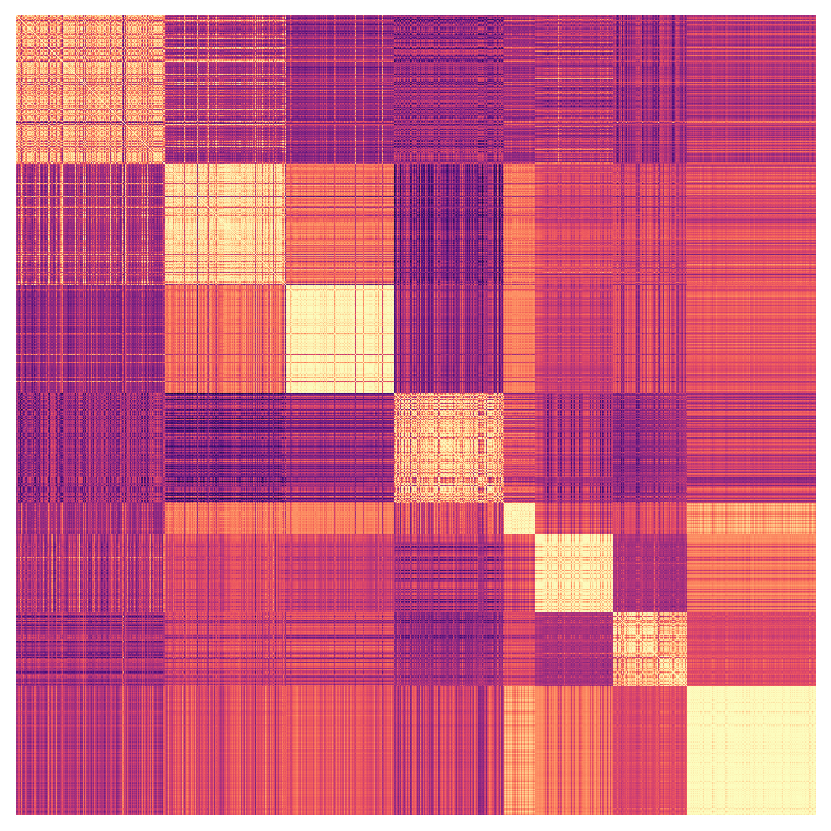

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from pathlib import Path

# Sort cells by their 'cell_type' annotation for better visualization
adata_heatmap = test_ad_rna[test_ad_rna.obs['cell_type'].argsort()]

# Extract cell embeddings from the 'scPMMI' representation
embeddings = adata_heatmap.obsm['scPMMI']

# Compute pairwise cosine similarity between all cells
similarity_matrix = cosine_similarity(embeddings, embeddings)

# -------------------------------------------------------------------------
# Plot heatmap
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(5, 5))  # Create a square figure

sns.heatmap(
    similarity_matrix,
    cmap="magma",               # Use a high-contrast scientific colormap
    xticklabels=False,          # Hide x-axis tick labels
    yticklabels=False,          # Hide y-axis tick labels
    cbar=False,                 # Hide colorbar (set True to show)
    cbar_kws={'shrink': 0.3, 'aspect': 5},  # Colorbar settings (if enabled)
    ax=ax,
    square=True                 # Force each cell to be square
)

# Remove all padding around the heatmap to fill the entire figure
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)

# Always save before showing to avoid blank figures in some backends
save_path = Path(save_path)  # Ensure save_path is a Path object
fig.savefig(save_path / "heatmap.png", dpi=300, transparent=True)

plt.show()
